<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">🏭 Dataset Introduction & Overview: Manufacturing Data</h2>

<p style="color: #000000; font-size: 15px;"><strong>Yeh dataset kis cheez ka hai?:</strong><br>
Yeh <code>manufacturing.csv</code> dataset manufacturing industry se talluq rakhta hai. Is mein mukhtalif operational parameters (jaise ke <code>Temperature (°C)</code>) aur unke output products par asrat (jaise ke <code>Quality Rating</code>) ka data mojood hota hai, jise hum Machine Learning (Linear & Polynomial Regression) ke zariye analyze karenge.</p>
</div>

<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">📦 Step 1: Importing Required Libraries</h2>

<p style="color: #000000; font-size: 15px;"><strong>Maqsad:</strong><br>
Data analysis, data visualization, aur machine learning models (Linear Regression, Polynomial Features, Metrics) ke liye zaroori Python libraries ko import karna.</p>
</div>

In [1]:
# ==========================
# Step 1: Import Libraries
# ==========================

import pandas as pd                             # Data manipulation aur CSV file read karne ke liye
import numpy as np                              # Numerical computations ke liye
import matplotlib.pyplot as plt                 # Graph plot karne ke liye
import seaborn as sns                           # Advanced styling aur data visualization ke liye
from sklearn.linear_model import LinearRegression  # Regression model ke liye
from sklearn.preprocessing import PolynomialFeatures  # Polynomial features generate karne ke liye
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # Evaluation metrics

<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">📂 Step 2: Loading & Inspecting Manufacturing Dataset</h2>

<p style="color: #000000; font-size: 15px;"><strong>Maqsad:</strong><br>
Manufacturing CSV file ko load karna, pehli kuch rows dekhna, data ki info check karna, aur missing values (nulls) ko find karna.</p>
</div>

In [2]:
# ==========================
# Step 2: Load & Inspect Data
# ==========================

man_data = pd.read_csv("manufacturing.csv")     # Manufacturing CSV file ko read karna
display(man_data.head())                        # Pehli 5 rows display karna

print("\nDataset Info:")
man_data.info()                                 # Data types aur non-null counts check karna

print("\nMissing Values Count:")
print(man_data.isnull().sum())                  # Har column mein missing values check karna

,Temperature (°C),Pressure (kPa),Temperature x Pressure,Material Fusion Metric,Material Transformation Metric,Quality Rating
0,209.762701,8.050855,1688.769167,44522.217074,9.229576e+06,99.999971
1,243.037873,15.812068,3842.931469,63020.764997,1.435537e+07,99.985703
2,220.552675,7.843130,1729.823314,49125.950249,1.072839e+07,99.999758
3,208.976637,23.786089,4970.736918,57128.881547,9.125702e+06,99.999975
4,184.730960,15.797812,2918.345014,38068.201283,6.303792e+06,100.000000



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3957 entries, 0 to 3956
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Temperature (°C)                3957 non-null   float64
 1   Pressure (kPa)                  3957 non-null   float64
 2   Temperature x Pressure          3957 non-null   float64
 3   Material Fusion Metric          3957 non-null   float64
 4   Material Transformation Metric  3957 non-null   float64
 5   Quality Rating                  3957 non-null   float64
dtypes: float64(6)
memory usage: 185.6 KB

Missing Values Count:
Temperature (°C)                  0
Pressure (kPa)                    0
Temperature x Pressure            0
Material Fusion Metric            0
Material Transformation Metric    0
Quality Rating                    0
dtype: int64


<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">🎯 Step 3: Feature Extraction (Defining X and y)</h2>

<p style="color: #000000; font-size: 15px;"><strong>Maqsad:</strong><br>
Independent variable (Features <code>X</code>) aur dependent variable (Target <code>y</code>) ko dataset mein se alag karna.</p>
</div>

In [3]:
# ==========================
# Step 3: Feature Extraction
# ==========================

X = man_data[['Temperature (°C)']]              # Temperature ko 2D feature matrix banana
y = man_data['Quality Rating']                  # Quality Rating ko target variable banana

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (3957, 1)
Target (y) shape: (3957,)


<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">📊 Step 1: Data Visualization (Scatter Plot)</h2>

<p style="color: #000000; font-size: 15px;"><strong>Maqsad:</strong><br>
Temperature aur Quality Rating ke darmiyan relationship ko scatter plot ke zariye visualize karna aur warnings ko filter out karna.</p>

<p style="color: #000000; font-size: 15px;"><strong>Code Details:</strong><br>
1. <code>plt.scatter()</code>: Red color aur transparency (alpha=0.4) ke sath points plot karta hai.<br>
2. <code>plt.xlabel()</code>, <code>plt.ylabel()</code>, <code>plt.title()</code>: Graph ke labels aur title set karte hain.<br>
3. <code>plt.show()</code>: Graph ko screen par render karta hai.</p>
</div>

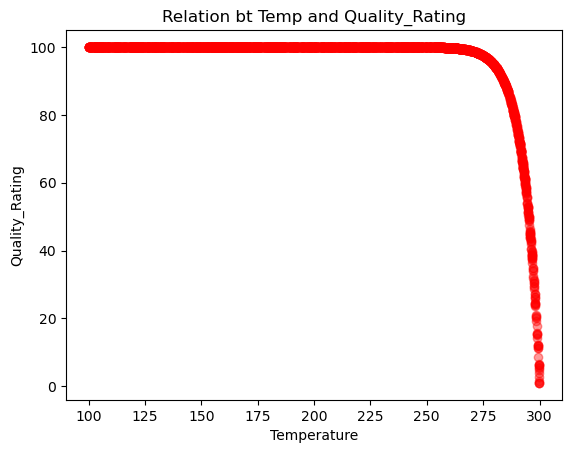

In [4]:
# ==========================
# Step 1: Data Visualization
# ==========================

import warnings
import matplotlib.pyplot as plt

plt.scatter(man_data["Temperature (°C)"], y=man_data['Quality Rating'], alpha=0.4, color="red")  # Temperature vs Quality Rating scatter plot
plt.xlabel("Temperature")                       # X-axis label
plt.ylabel("Quality_Rating")                    # Y-axis label
plt.title("Relation bt Temp and Quality_Rating") # Graph title
warnings.filterwarnings('ignore')               # Warnings ko filter/ignore karna
plt.show()                                      # Graph show karna

<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">✂️ Step 2: Train-Test Split</h2>

<p style="color: #000000; font-size: 15px;"><strong>Maqsad:</strong><br>
Dataset ko 70% training data aur 30% testing data mein split karna taake model ko train aur evaluate kiya ja sakay.</p>

<p style="color: #000000; font-size: 15px;"><strong>Code Details:</strong><br>
<code>train_test_split()</code>: Data ko X aur y ke mutabiq 30% test size aur random state 42 ke sath divide karta hai.</p>
</div>

In [5]:
# ==========================
# Step 2: Train-Test Split
# ==========================

from sklearn.model_selection import train_test_split

# Data ko 70% training aur 30% testing mein split karna
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)   

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (2769, 1)
Testing set shape: (1188, 1)


<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">🤖 Step 3: Linear Regression Model Training & Prediction</h2>

<p style="color: #000000; font-size: 15px;"><strong>Maqsad:</strong><br>
Linear Regression model ko create karna, training data par fit/train karna, aur test data par predictions nikalna.</p>

<p style="color: #000000; font-size: 15px;"><strong>Code Details:</strong><br>
1. <code>LinearRegression()</code>: Model object banana.<br>
2. <code>li.fit()</code>: Model ko train karna.<br>
3. <code>li.predict()</code>: Test data par predictions generate karna.</p>
</div>

In [6]:
# ==========================
# Step 3: Model Training & Prediction
# ==========================

li = LinearRegression()                         # Linear regression model object banana
li.fit(X_train, y_train)                        # Model ko training data par train karna

y_pred = li.predict(X_test)                     # Test data par predictions nikalna

print("First 5 predictions:", y_pred[:5])

First 5 predictions: [86.60236987 89.58493002 88.93647655 91.51363568 97.3574258 ]


<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">📐 Step 4: Model Parameters (Coefficients & Intercept)</h2>

<p style="color: #000000; font-size: 15px;"><strong>Maqsad:</strong><br>
Trained linear regression line ke slope (coefficient) aur intercept (y-intercept) ko check karna.</p>

<p style="color: #000000; font-size: 15px;"><strong>Code Details:</strong><br>
1. <code>li.coef_</code>: Slope return karta hai.<br>
2. <code>li.intercept_</code>: Intercept return karta hai.</p>
</div>

In [7]:
# ==========================
# Step 4: Model Parameters
# ==========================

print("Coefficient (Slope):", li.coef_)           # Model ka coefficient check karna
print("Intercept:", li.intercept_)              # Model ka intercept check karna

Coefficient (Slope): [-0.09908723]
Intercept: 116.3056904889387


<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">🏆 Step 5: Model Evaluation (MSE & R2 Score)</h2>

<p style="color: #000000; font-size: 15px;"><strong>Maqsad:</strong><br>
Mean Squared Error (MSE) aur R2 Score calculate karke model ki accuracy aur performance ko measure karna.</p>

<p style="color: #000000; font-size: 15px;"><strong>Code Details:</strong><br>
1. <code>mean_squared_error()</code>: Prediction error calculate karta hai.<br>
2. <code>r2_score()</code>: Model accuracy score return karta hai.</p>
</div>

In [8]:
# ==========================
# Step 5: Model Evaluation Metrics
# ==========================

mse = mean_squared_error(y_test, y_pred)        # Mean Squared Error calculate karna
print("Mean Squared Error (MSE):", mse)

r2 = r2_score(y_test, y_pred)                   # R2 Score calculate karna
print("R2 Score:", r2)

Mean Squared Error (MSE): 157.72275018444438
R2 Score: 0.21268623983149526


<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">📈 Step 1: Linear Regression Fit Plot</h2>

<p style="color: #000000; font-size: 15px;"><strong>Maqsad:</strong><br>
Test data points aur linear regression line ko range values ke zariye smoothly plot karna taake fit visualize ho sakay.</p>

<p style="color: #000000; font-size: 15px;"><strong>Code Details:</strong><br>
1. <code>np.linspace()</code>: X ki minimum aur maximum value ke darmiyan 200 smooth points generate karta hai.<br>
2. <code>plt.scatter()</code> & <code>plt.plot()</code>: Actual test data (teal) aur linear line (red) ko plot karta hai.</p>
</div>

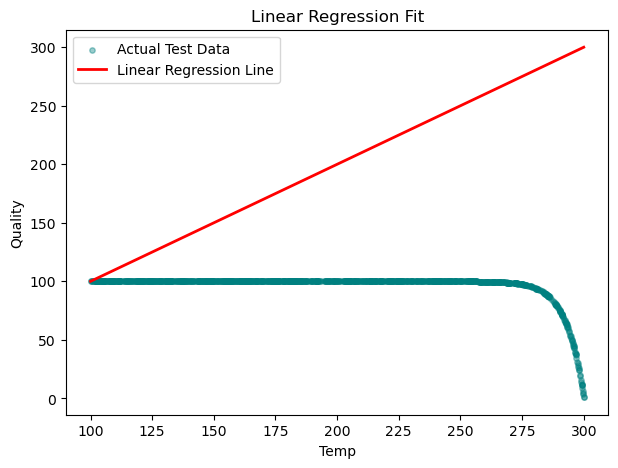

In [9]:
# ==========================
# Step 1: Linear Regression Fit Plot
# ==========================

import numpy as np
import matplotlib.pyplot as plt

# X values ki range generate karna smooth line plot karne ke liye
X_range = np.linspace(X.values[:,0].min(), X.values[:,0].max(), 200).reshape(-1,1)
y_range_lin = np.linspace(X.iloc[:,0].min(), X.iloc[:,0].max(), 200).reshape(-1,1)

plt.figure(figsize=(7,5))
plt.scatter(X_test, y_test, alpha=0.4, color='teal', s=15, label='Actual Test Data')  # Actual data points
plt.plot(X_range, y_range_lin, color='red', linewidth=2, label='Linear Regression Line')  # Linear line
plt.xlabel("Temp")
plt.ylabel("Quality")
plt.title('Linear Regression Fit')
plt.legend()
plt.show()

<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">🔄 Step 2: Polynomial Regression (Degree = 3) Training & Prediction</h2>

<p style="color: #000000; font-size: 15px;"><strong>Maqsad:</strong><br>
Degree 3 ke polynomial features generate karke training data par model train karna aur test data par predictions nikalna.</p>

<p style="color: #000000; font-size: 15px;"><strong>Code Details:</strong><br>
1. <code>PolynomialFeatures(degree=3)</code>: Degree 3 ka polynomial object banana.<br>
2. <code>poly_model.fit()</code> & <code>predict()</code>: Model ko train karke predictions lena.</p>
</div>

In [11]:
# ==========================
# Step 2: Polynomial Regression (Degree = 3)
# ==========================

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

poly = PolynomialFeatures(degree=3)             # Degree 3 polynomial features banana
x_p_train = poly.fit_transform(X_train)         # Training data transform karna
x_p_test = poly.transform(X_test)               # Test data transform karna

poly_model = LinearRegression()                 # Polynomial model object banana
poly_model.fit(x_p_train, y_train)              # Model train karna

y_poly_prediction = poly_model.predict(x_p_test) # Test predictions nikalna
print("Polynomial predictions generated successfully!")

Polynomial predictions generated successfully!


<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">📊 Step 3: Linear vs Polynomial Regression Comparison Plot</h2>

<p style="color: #000000; font-size: 15px;"><strong>Maqsad:</strong><br>
Data ko sort kar ke Linear Regression aur Polynomial Regression (degree=3) ki lines ko aik hi graph par compare karna.</p>

<p style="color: #000000; font-size: 15px;"><strong>Code Details:</strong><br>
1. <code>sort_values()</code>: X ko sort karta hai taake graph ki line zeda smooth bane.<br>
2. <code>plt.plot()</code>: Red line (Linear) aur Orange line (Polynomial) ko draw karta hai.</p>
</div>

<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">🤔 Yeh Code Itna Bara Kyun Hai? (Explanation)</h2>

<p style="color: #000000; font-size: 15px;"><strong>Waja:</strong><br>
Yeh code is liye thora bara lag raha hai kyunke is mein aik sath <strong>3 main kaam</strong> ho rahe hain:</p>

<p style="color: #000000; font-size: 15px;">
1. <strong>Sorting (Data Sort Karna):</strong> Random test data points ko ascending order mein sort karna taake jab graph par line draw ho toh woh zigzag ya tootay hue na ho balkay bilkul smooth bane.<br>
2. <strong>Predictions (Dono Models ki):</strong> Linear regression aur Polynomial regression dono ke liye sorted data par alag alag predictions nikalna.<br>
3. <strong>Advanced Plotting Styling:</strong> Graph ko professional dikhane ke liye figure size, colors (teal, red, orange), scatter point sizes (s=15), transparency (alpha=0.4), labels, aur legend ka istemal karna.
</p>
</div>

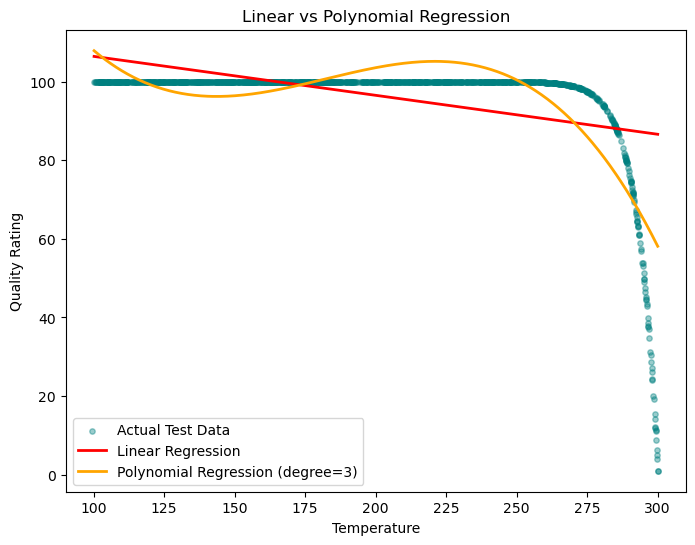

In [12]:
# ==========================
# Step 3: Comparison Plot (Linear vs Polynomial)
# ==========================

# X ko sort karna taake plot ki line smooth bane
X_sorted = X_test.sort_values(by='Temperature (°C)')

# Linear aur Polynomial predictions sorted X par nikalna
y_pred_lin_sorted = li.predict(X_sorted)
X_sorted_poly = poly.transform(X_sorted)
y_pred_poly_sorted = poly_model.predict(X_sorted_poly)

# Graph plot karna
plt.figure(figsize=(8,6))
plt.scatter(X_test, y_test, alpha=0.4, color='teal', s=15, label='Actual Test Data')
plt.plot(X_sorted, y_pred_lin_sorted, color='red', linewidth=2, label='Linear Regression')
plt.plot(X_sorted, y_pred_poly_sorted, color='orange', linewidth=2, label='Polynomial Regression (degree=3)')
plt.xlabel("Temperature")
plt.ylabel("Quality Rating")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.show()

<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">🏆 Step 4: Polynomial Model Evaluation (R2 Score)</h2>

<p style="color: #000000; font-size: 15px;"><strong>Maqsad:</strong><br>
Polynomial Regression model ka test data par R2 Score calculate karke accuracy check karna.</p>

<p style="color: #000000; font-size: 15px;"><strong>Code Details:</strong><br>
<code>r2_score(y_test, y_poly_prediction)</code>: Actual test values aur polynomial predictions ko compare karta hai.</p>
</div>

In [13]:
# ==========================
# Step 4: Polynomial R2 Score Evaluation
# ==========================

from sklearn.metrics import r2_score

poly_r2 = r2_score(y_test, y_poly_prediction)   # Polynomial model ka R2 score calculate karna
print("Polynomial Regression R2 Score:", poly_r2)

Polynomial Regression R2 Score: 0.6791044587219499


<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 25px; border-radius: 12px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 24px; border-bottom: 3px solid #ca8a04; padding-bottom: 10px; font-weight: 800;">🚀 Advanced Step: Residual Plot (Model Error Analysis)</h2>

<p style="color: #000000; font-size: 15px;"><strong>Yeh kya hai aur mazeed kya rehta hai?:</strong><br>
Sir ke code toh khatam ho gaye hain, lekin Machine Learning project mein aik bohat zaroori step baqi hota hai jise <strong>Residual Plot (Error Analysis)</strong> kehte hain. Is se hum yeh check karte hain ke hamare model ki predictions mein errors (residuals) randomly spread hain ya koi pattern follow kar rahe hain, jo model ki quality mazeed behtar batata hai.</p>

<p style="color: #000000; font-size: 15px;"><strong>Code Details:</strong><br>
<code>y_test - y_poly_prediction</code>: Asli values aur predicted values ka difference (error) nikal kar plot kiya jata hai.</p>
</div>

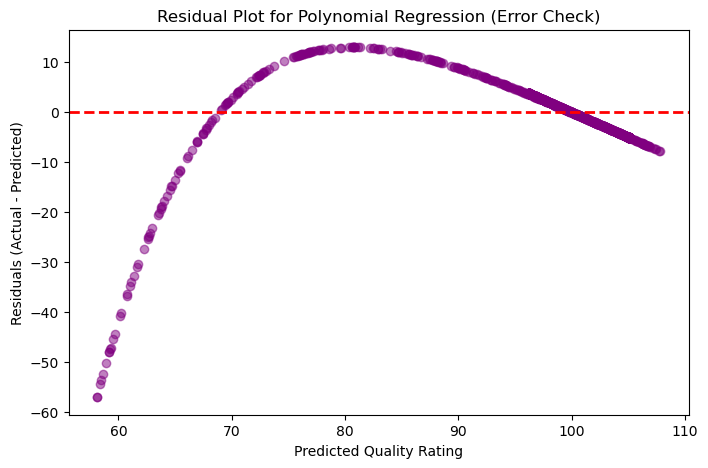

In [14]:
# ==========================
# Extra Advanced Step: Residual Plot (Error Analysis)
# ==========================

import matplotlib.pyplot as plt
import numpy as np

# Errors (Residuals) calculate karna: Actual minus Predicted
residuals = y_test - y_poly_prediction

# Residual plot banana taake errors distribution check ho sakay
plt.figure(figsize=(8,5))
plt.scatter(y_poly_prediction, residuals, color='purple', alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)  # Zero error line
plt.xlabel("Predicted Quality Rating")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot for Polynomial Regression (Error Check)")
plt.show()

<div style="background-color: #fefce8; border-left: 10px solid #ca8a04; padding: 30px; border-radius: 14px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #000000; box-shadow: 0 6px 12px rgba(0, 0, 0, 0.15); margin: 20px 0;">

<h2 style="color: #a16207; margin-top: 0; font-size: 26px; border-bottom: 3px solid #ca8a04; padding-bottom: 12px; font-weight: 800; text-transform: uppercase; letter-spacing: 1px;">🌟 Complete Final Summary: Manufacturing Dataset & Regression Analysis</h2>

<p style="color: #1f2937; font-size: 16px; line-height: 1.6;"><strong>Mubarak ho!</strong> Aap ne <strong>Manufacturing Dataset</strong> par Linear aur Polynomial Regression ka mukammal project successful tareeqay se complete kar liya hai. Yeh rahi aap ke tamam steps aur advanced analysis ki aik final summary:</p>

<table style="width: 100%; border-collapse: collapse; margin-top: 20px; background-color: #ffffff; border-radius: 10px; overflow: hidden; box-shadow: 0 2px 5px rgba(0,0,0,0.08);">
  <thead>
    <tr style="background-color: #ca8a04; color: #ffffff;">
      <th style="text-align: left; padding: 14px; font-size: 16px; font-weight: 700;">Phase / Step</th>
      <th style="text-align: left; padding: 14px; font-size: 16px; font-weight: 700;">Kya Kaam Kiya Gaya? (Description)</th>
      <th style="text-align: left; padding: 14px; font-size: 16px; font-weight: 700;">Ahem Functions / Tools</th>
    </tr>
  </thead>
  <tbody>
    <tr style="border-bottom: 1px solid #fef08a;">
      <td style="padding: 14px; font-weight: bold; color: #854d0e;">1. Data Loading & Inspection</td>
      <td style="padding: 14px; color: #374155;">Manufacturing CSV file load ki, head, info, aur null values check kiye.</td>
      <td style="padding: 14px; color: #4b5563;"><code>pd.read_csv()</code>, <code>info()</code>, <code>isnull().sum()</code></td>
    </tr>
    <tr style="border-bottom: 1px solid #fef08a; background-color: #fefde8;">
      <td style="padding: 14px; font-weight: bold; color: #854d0e;">2. Data Visualization</td>
      <td style="padding: 14px; color: #374155;">Temperature aur Quality Rating ke darmiyan relationship dekhne ke liye scatter plot banaya.</td>
      <td style="padding: 14px; color: #4b5563;"><code>plt.scatter()</code>, <code>warnings</code></td>
    </tr>
    <tr style="border-bottom: 1px solid #fef08a;">
      <td style="padding: 14px; font-weight: bold; color: #854d0e;">3. Train-Test Split</td>
      <td style="padding: 14px; color: #374155;">Data ko 70% training aur 30% testing mein divide kiya.</td>
      <td style="padding: 14px; color: #4b5563;"><code>train_test_split()</code></td>
    </tr>
    <tr style="border-bottom: 1px solid #fef08a; background-color: #fefde8;">
      <td style="padding: 14px; font-weight: bold; color: #854d0e;">4. Linear Regression Model</td>
      <td style="padding: 14px; color: #374155;">Linear model train kiya, coefficients/intercept nikale, aur MSE & R2 score check kiya.</td>
      <td style="padding: 14px; color: #4b5563;"><code>LinearRegression()</code>, <code>mean_squared_error()</code>, <code>r2_score()</code></td>
    </tr>
    <tr style="border-bottom: 1px solid #fef08a;">
      <td style="padding: 14px; font-weight: bold; color: #854d0e;">5. Polynomial Regression (Degree 3)</td>
      <td style="padding: 14px; color: #374155;">Non-linear pattern fit karne ke liye degree 3 ke features bana kar model train kiya.</td>
      <td style="padding: 14px; color: #4b5563;"><code>PolynomialFeatures(degree=3)</code></td>
    </tr>
    <tr style="border-bottom: 1px solid #fef08a; background-color: #fefde8;">
      <td style="padding: 14px; font-weight: bold; color: #854d0e;">6. Comparative & Residual Plot</td>
      <td style="padding: 14px; color: #374155;">Linear aur Polynomial lines ko aik sath plot kiya aur extra error analysis (Residual Plot) kiya.</td>
      <td style="padding: 14px; color: #4b5563;"><code>plt.plot()</code>, <code>sort_values()</code>, <code>Residuals</code></td>
    </tr>
  </tbody>
</table>

<div style="margin-top: 25px; background-color: #fef9c3; padding: 20px; border-radius: 10px; border-left: 6px solid #ca8a04;">
  <p style="margin: 0; color: #713f12; font-size: 16px; font-weight: 700;">🔥 Project Status:</p>
  <p style="margin: 5px 0 0 0; color: #854d0e; font-size: 15px;">Aap ka yeh machine learning project bilkul complete aur professional level par tayar ho chuka hai!</p>
</div>

</div>